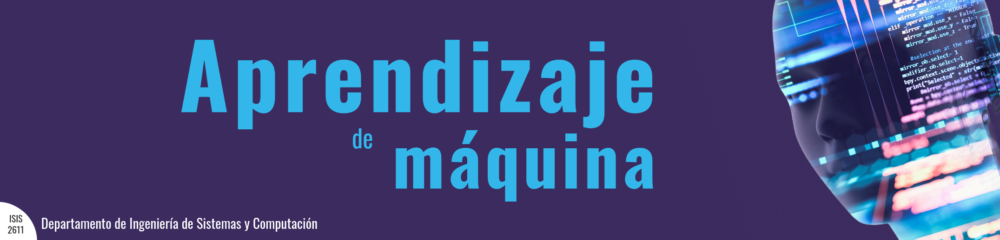

# Segmentación de Imágenes con K-Means

En la práctica anterior se analizó una de las aplicaciones más frecuentes de los algoritmos de agrupación: el perfilamiento de usuarios mediante la identificación de patrones en sus datos para mejorar su experiencia y encontrar oportunidades de mercadeo. Sin embargo, este notebook tiene como objetivo explorar otro caso de uso dentro del área de la visión por computadora. Específicamente, cómo aplicar el algoritmo K-Means para la segmentación de imágenes.

Las imágenes digitales se representan típicamente como arreglos de dimensiones $H \times W \times C$, donde $H$ y $W$ corresponden a la altura y anchura en píxeles, mientras que $C$ denota los canales de color (usualmente 3 para el espacio *RGB*). Para abordar la segmentación como un problema de agrupamiento, la estructura se transforma en un conjunto de datos de tamaño $(H \cdot W) \times C$. En este nuevo espacio, los valores de color de cada píxel actúan como coordenadas en $\mathbb{R}^3$, permitiendo que los algoritmos identifiquen patrones basados en la intensidad y similitud cromática.

Para ello, se han seleccionado diez imágenes de manera arbitraria. El objetivo es analizar la aplicación de esta técnica y evaluar la calidad de los resultados que el algoritmo es capaz de producir en diferentes escenarios.



A continuación, se llevará a cabo una exploración del conjunto de imágenes para, posteriormente, proceder con el entrenamiento y la evaluación de los modelos de segmentación.

Para ello este notebook se divide en:

1. Importación de librerías.
2. Carga de datos.
3. Exploración de datos.
4. Selección de imagen.
5. Entrenamiento y evaluación.
6. Ejercicios

## 0. Instalación de librerías

In [1]:
# Si no tienes la linería OpenCV instalada debes primero ejecutar este paso:
# pip install opencv-python

## 1. Importación de librerías

In [2]:
import os
import cv2

import numpy as np
from glob import glob

import plotly.graph_objects as go
from matplotlib import pyplot as plt

from sklearn.cluster import KMeans

## 2. Carga de datos.

Las imágenes se encuentran en el directorio `/data`, por lo que se recuperan las rutas de los archivos contenidos en dicha carpeta para cargarlos en memoria.

In [3]:
img_paths = sorted(glob(os.path.join('.', 'data', '*.jpg')))

In [4]:
def load_imgs(paths):
  imgs = []
  for path in paths:
    imgs.append(cv2.imread(path, cv2.IMREAD_COLOR_RGB))
  return imgs

In [5]:
imgs = load_imgs(img_paths)

## 3. Exploración de datos


Una vez con los datos cargados, se procede a explorarlos con el fin de observar su estructura y distribución:

In [6]:
len(imgs)

10

Se comprueba que los datos contienen tan solo diez imágenes. De manera que, al tratarse de un conjunto bastante pequeño, se procede a visulizarlas.

In [7]:
def show_imgs(imgs, title):
  cols = len(imgs)//2
  rows = len(imgs)//cols


  fig, ax = plt.subplots(rows, cols, layout='tight', figsize=(12, 8))

  img_idx = 0
  for i in range(rows):
    for j in range(cols):
      ax[i, j].imshow(imgs[img_idx])
      ax[i, j].axis('off')

      img_idx += 1

  plt.suptitle(title)
  plt.show()

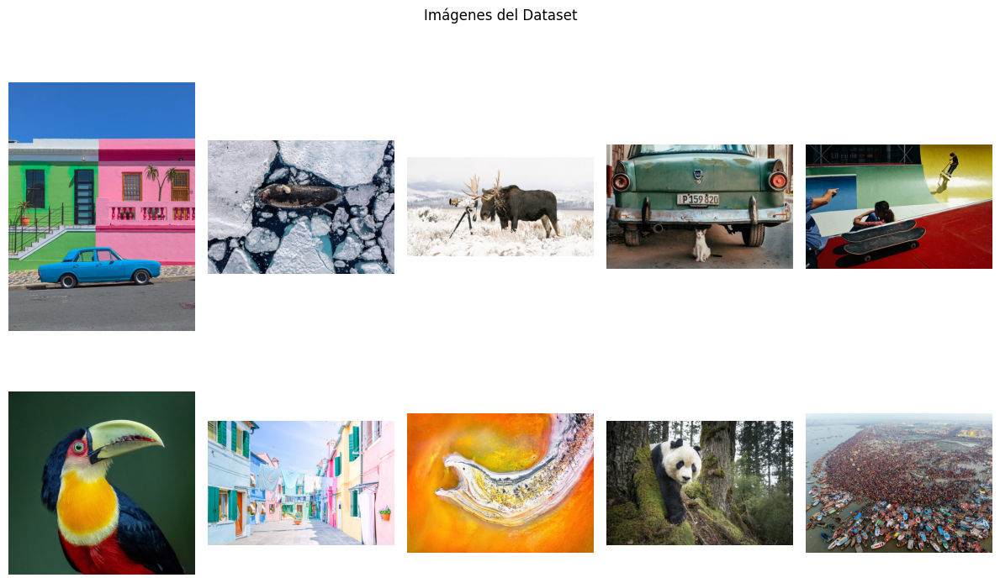

In [8]:
show_imgs(imgs, 'Imágenes del Dataset')

Se observa que el conjunto consiste en una colección diversa de imágenes que cubren distintas áreas del espectro cromático. Esta variedad resulta ideal para poner a prueba los modelos de agrupación ante diferentes distribuciones de color.

## 4. Selección de imagen.



Dado que el objetivo es analizar la respuesta del modelo ante cada imagen individual, el entrenamiento se realizará píxel a píxel por cada imagen, en lugar de utilizar el conjunto completo. No obstante, en dominios donde las imágenes comparten una misma distribución cromática, puede que sea preferible entrenar el modelo sobre todo el conjunto.

Debido a ello se selecciona una imagen de forma aleatoria, sin embargo, también es posible seleccionar una imágen en particualr si es que se desea explorarla.

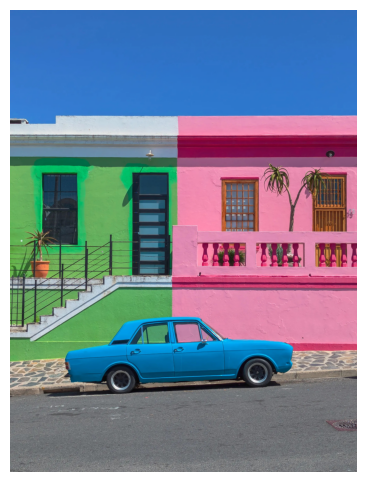

In [9]:
img_idx = 0  # fijamos un índice para que el análisis sea reproducible entre ejecuciones
img = imgs[img_idx]

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(img)
ax.axis('off')

plt.show()

In [10]:
def plot_data(img, pct=0.01):

    X = img.reshape(-1, 3)
    X_idx_sample = np.random.choice(len(X), round(len(X)*pct), replace=False)
    X_sample = X[X_idx_sample]

    r, g, b = X_sample[:, 0], X_sample[:, 1], X_sample[:, 2]
    colors = [f'rgb({r},{g},{b})' for r, g, b in X_sample]

    fig = go.Figure(data=[go.Scatter3d(
        x=r, y=g, z=b,
        mode='markers',
        marker=dict(
            size=2,
            color=colors,
            opacity=0.8
        )
    )])


    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=0), # Tight layout
        scene=dict(xaxis_title='R', yaxis_title='G', zaxis_title='B')
    )

    fig.show()

Tras seleccionar una imagen, se procede a visualizar su distribución en el espacio RGB. El objetivo es analizar la morfología del conjunto de datos mediante una gráfica interactiva que permita identificar cómo se agrupan los colores.

In [11]:
plot_data(img)

Se observa que la distribución del conjunto es considerablemente anisotrópica. Al presentar agrupaciones que no siguen una distribución normal, los datos adquieren formas complejas que, a simple vista, representan un desafío para los algoritmos de clustering tradicionales.

## 5. Entrenamiento y evaluación.

### Segmentación por color

Para la segmentación, se ejecutará el algoritmo K-Means y se generará una nueva imagen donde cada píxel adoptará el color del centroide de su clúster asignado. Este procedimiento se repetirá variando el valor de $K$, lo que permitirá evaluar cualitativamente el impacto de este hiperparámetro en el resultado de la segmentación.

In [12]:
def img_segmentation(img, k_vals):

  X = img.reshape((-1, 3))

  segmented_imgs = np.zeros((len(k_vals), *img.shape), dtype=np.uint8)
  kmeans_list = []

  for i, k in enumerate(k_vals):

    kmeans = KMeans(n_clusters=k)
    cluster_labels = kmeans.fit_predict(X)
    segmented_pixels = kmeans.cluster_centers_[cluster_labels]
    segmented_img = segmented_pixels.reshape(img.shape)
    segmented_imgs[i] = segmented_img
    kmeans_list.append(kmeans)

  return segmented_imgs, kmeans_list

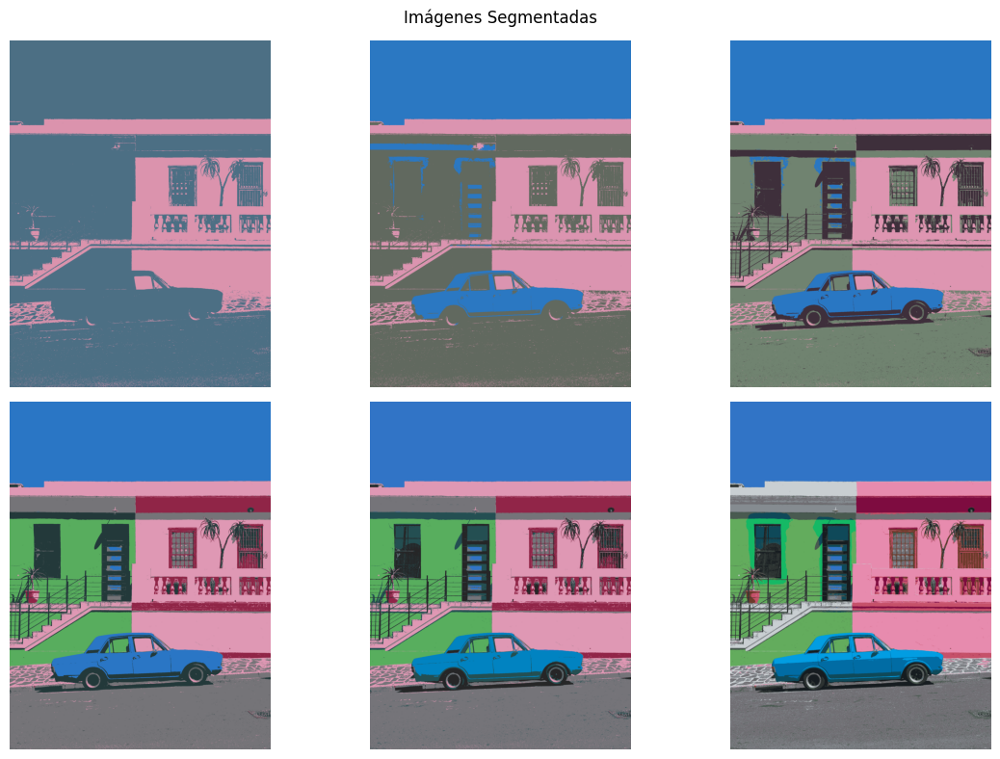

In [13]:
k_vals = [2, 3, 4, 6, 8, 16]
segmented_imgs, kmeans_list = img_segmentation(img, k_vals)
show_imgs(segmented_imgs, 'Imágenes Segmentadas')

Este proceso genera imágenes que mantienen su estructura original con una paleta de colores simplificada. Es notable como, al superar un valor de $K=8$, la fidelidad es tal que los cambios apenas se perciben a simple vista. Esto abre la puerta a usos prácticos como la compresión mediante cuantización o la creación de representaciones simplificadas para otros algoritmos de visión artificial. Sin embargo, en un contexto donde la capacidad de cómputo ya no es una limitación crítica, esta técnica destaca hoy por su valor estético y artístico.

In [14]:
def elbow_plot(kmeans_list):

    k_vals = []
    inertia_vals = []
    for kmeans in kmeans_list:
      k_vals.append(kmeans.n_clusters)
      inertia_vals.append(kmeans.inertia_)

    plt.plot(k_vals, inertia_vals, marker='o')
    plt.xlabel('Número de clústeres')
    plt.ylabel('Inercia')
    plt.title('Método del Codo')
    plt.grid()
    plt.show()

    return inertia_vals, k_vals

Para profundizar en el análisis desde una perspectiva cuantitativa, es posible emplear las métricas de evaluación estudiadas previamente. Métodos como el método del codo o el coeficiente de silueta permiten realizar la selección del hiperparámetro $K$ basándose en la estructura interna de los datos, más allá de la inspección visual.

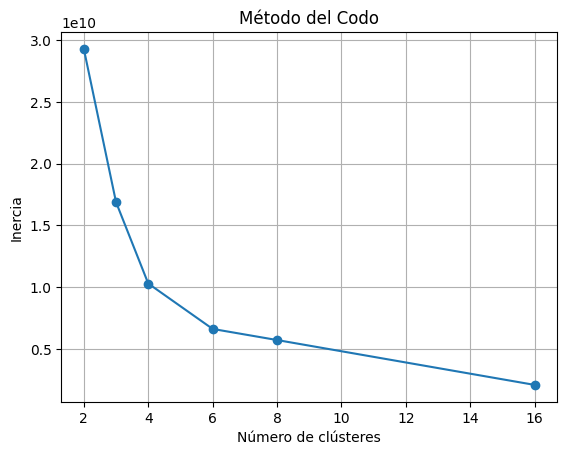

In [15]:
inertia_vals, k_vals = elbow_plot(kmeans_list)

Con el fin de automatizar la elección de $K$, buscamos el 'codo' de la gráfica determinando su cambio de pendiente más brusco. Para ello, calculamos el máximo del valor absoluto de la segunda derivada de la inercia. Este valor nos indica el punto donde añadir más clústeres deja de aportar una mejora significativa.

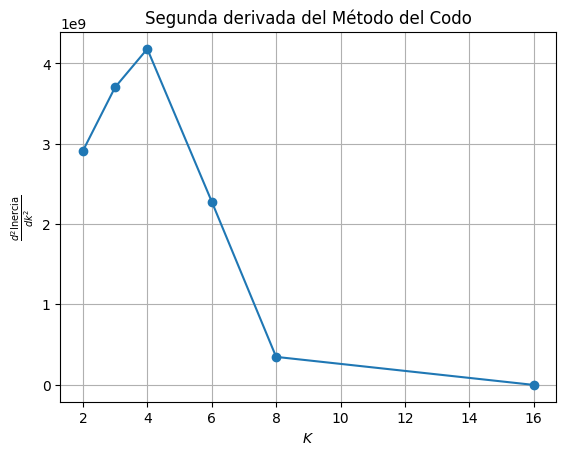

In [16]:
ddinertia = np.gradient(np.gradient(np.abs(inertia_vals), k_vals))

plt.plot(k_vals, ddinertia, marker='o')
plt.xlabel('$K$')
plt.ylabel(r'$\frac{d^2 \text{Inercia}}{dk^2}$')
plt.title('Segunda derivada del Método del Codo')
plt.grid()
plt.show()

In [17]:
optimal_k =  k_vals[np.argmax(ddinertia)]
optimal_k

4

Finalmente, tras determinar el valor óptimo de $K$, se procede a graficar nuevamente la distribución de los datos. Esta visualización permite contrastar los clústeres generados con la estructura original de los píxeles, facilitando la interpretación geométrica de la segmentación obtenida.

In [18]:
def plot_seg_data(img, k, pct=0.01):

    X = img.reshape(-1, 3)

    kmeans = KMeans(n_clusters=k)
    cluster_labels = kmeans.fit_predict(X)
    segmented_pixels = kmeans.cluster_centers_[cluster_labels]


    X_idx_sample = np.random.choice(len(X), round(len(X)*pct), replace=False)
    X_sample = X[X_idx_sample]
    segmented_sample = segmented_pixels[X_idx_sample]

    r, g, b = X_sample[:, 0], X_sample[:, 1], X_sample[:, 2]

    colors = [f'rgb({r},{g},{b})' for r, g, b in segmented_sample]

    fig = go.Figure(data=[go.Scatter3d(
        x=r, y=g, z=b,
        mode='markers',
        marker=dict(
            size=2,
            color=colors,
            opacity=0.8
        )
    )])

    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=0), # Tight layout
        scene=dict(xaxis_title='R', yaxis_title='G', zaxis_title='B')
    )

    fig.show()

In [19]:
plot_seg_data(img, optimal_k)

Se observa que K-Means identifica los $K$ clústeres más representativos de la distribución mediante centroides cromáticamente diferenciados. No obstante, la morfología del espacio revela fronteras abruptas en regiones densas que podrían pertenecer a un mismo conjunto. Esto evidencia las limitaciones del algoritmo al imponer una partición rígida sobre los datos y destaca su sesgo hacia la identificación de conjuntos convexos.

### Segmentación por color y espacio

La segmentación anterior demuestra que K-Means identifica eficazmente los colores predominantes de una imagen. No obstante, evidencia que estos no poseen una correlación espacial intrínseca. Para aplicaciones prácticas, esta es una debilidad crítica, ya que la información estructural suele ser más relevante que la cromática. Por ejemplo, en una radiografía, distintos huesos pueden presentar la misma intensidad de color y recibir la misma etiqueta, a pesar de ser entidades anatómicas independientes.

Debido a las limitaciones mencionadas, resulta conveniente integrar información espacial en la representación de los píxeles. Bajo una metodología similar a la anterior, cada píxel se define por sus valores RGB, pero extendiendo el vector original con sus coordenadas cartesianas $(i,j)$. Esto genera un conjunto de datos en $\mathbb{R}^5$ que combina información cromática y espacial, permitiendo al algoritmo considerar la proximidad física de los píxeles.

En el siguiente ejemplo, se realizará la segmentación del vehículo en la imagen `0.jpg`. El procedimiento se llevará a cabo en dos etapas: primero, utilizando únicamente la información cromática y, posteriormente, integrando la información espacial. Esto permitirá demostrar el impacto que tiene la inclusión de las coordenadas en la precisión del modelo.

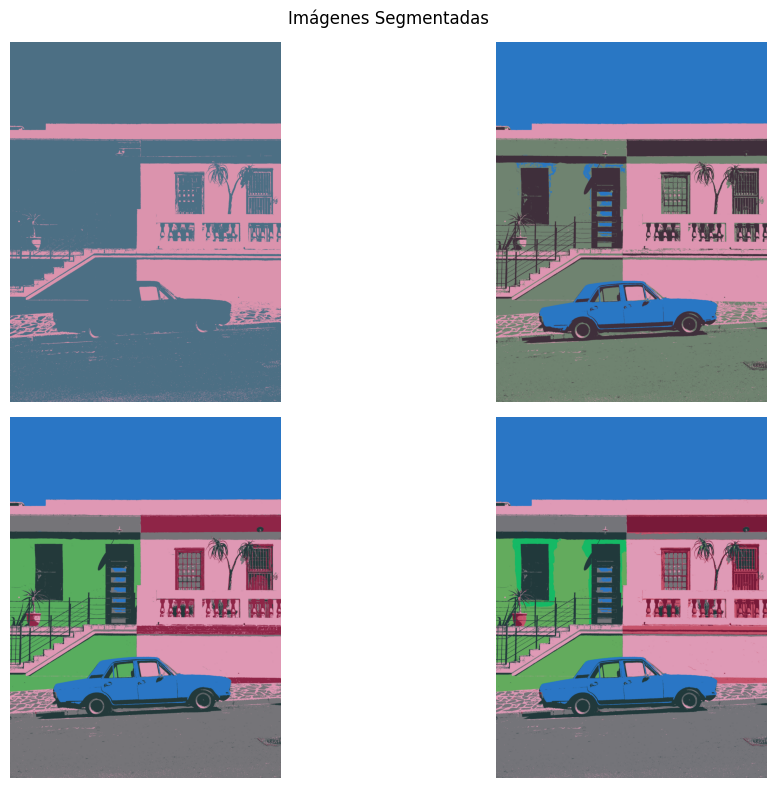

In [20]:
k_vals = [2, 4, 6, 8]
segmented_imgs, kmeans_list = img_segmentation(imgs[0], k_vals)
show_imgs(segmented_imgs, 'Imágenes Segmentadas')

Con base a la visualización de las imágenes se determina que con $K=4$ es posible segmentar el vehículo.

In [21]:
def get_img_masks(img, k, weight = 0.17):
  I, J = np.meshgrid(np.arange(img.shape[0]), np.arange(img.shape[1]), indexing='ij')
  idx_list = np.dstack([I, J]).reshape(-1, 2)

  X = img.reshape((-1, 3))
  X = np.hstack([X, idx_list*weight])

  kmeans = KMeans(n_clusters=k, random_state=2)
  cluster_labels = kmeans.fit_predict(X)

  segmented_img = cluster_labels.reshape(img.shape[:2])

  cols = k//2
  rows = k//cols

  fig, ax = plt.subplots(rows, cols, layout='tight', figsize=(10, 6))

  img_idx = 0

  for i in range(rows):
    for j in range(cols):

      mask = (segmented_img == img_idx)
      ax[i, j].imshow(mask)
      ax[i, j].axis('off')
      ax[i, j].set(title=f'Label = {img_idx}')

      img_idx += 1

  plt.show()

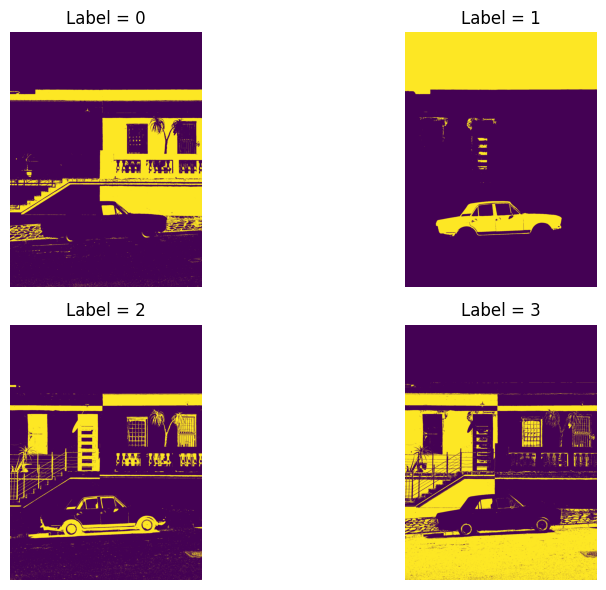

In [22]:
segmented_img = get_img_masks(imgs[0], 4, 0)

Las máscaras obtenidas demuestran que el algoritmo segmenta el vehículo correctamente. No obstante, también incluye áreas del cielo que poseen un color similar. Este resultado sugiere que el método tiene una alta cobertura, pero una baja precisión. Para mitigar este problema, se procederá a integrar las coordenadas espaciales en la representación de los píxeles, buscando diferenciar regiones cromáticamente similares pero espacialmente distantes.

In [23]:
def spatial_img_segmentation(img, k_vals, weight = 0.17):
  I, J = np.meshgrid(np.arange(img.shape[0]), np.arange(img.shape[1]), indexing='ij')
  idx_list = np.dstack([I, J]).reshape(-1, 2)

  X = img.reshape((-1, 3))
  X = np.hstack([X, idx_list*weight])

  segmented_imgs = np.zeros((len(k_vals), *img.shape), dtype=np.uint8)

  for i, k in enumerate(k_vals):

    kmeans = KMeans(n_clusters=k, random_state=2)
    cluster_labels = kmeans.fit_predict(X)
    segmented_pixels = kmeans.cluster_centers_[cluster_labels]

    segmented_img = segmented_pixels[:, :3].reshape(img.shape)
    segmented_imgs[i] = segmented_img

  return segmented_imgs

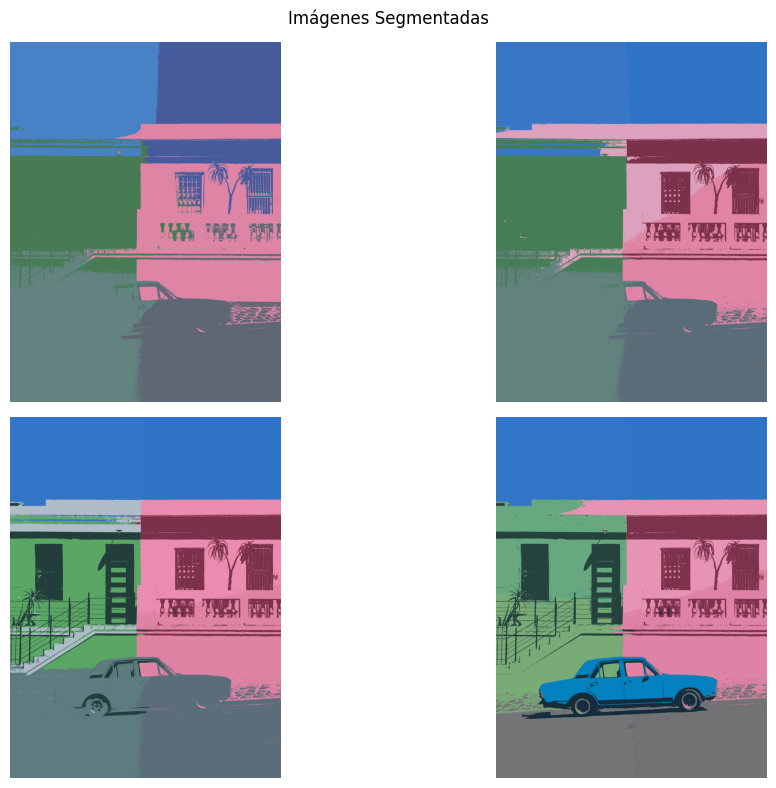

In [24]:
k_vals = [6, 8, 10, 12]
segmented_imgs = spatial_img_segmentation(imgs[0], k_vals)
show_imgs(segmented_imgs, 'Imágenes Segmentadas')

Se determina que con $K = 12$ es posible segmentar al vehículo. Por lo que se procede a extraer las máscaras de segmentación.

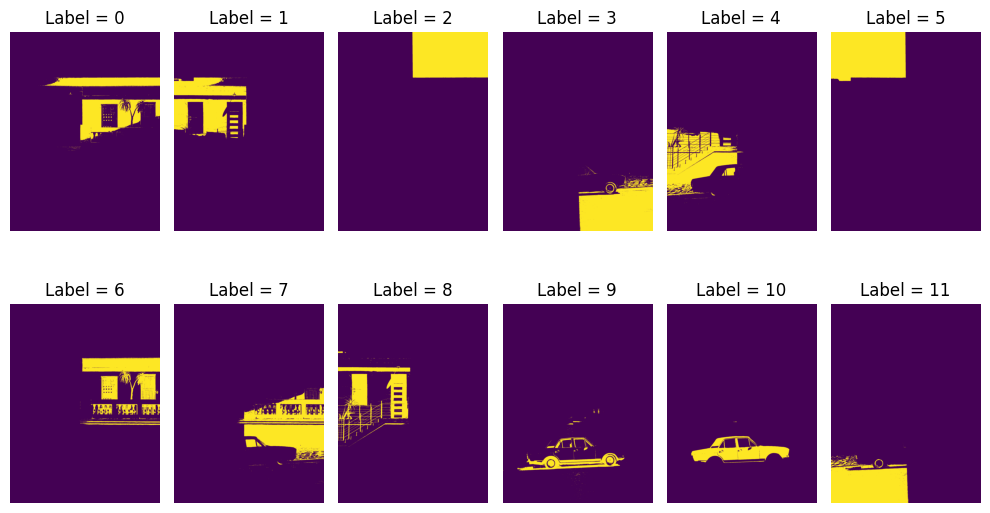

In [25]:
segmented_img = get_img_masks(imgs[0], 12)

Al visualizar las máscaras de segmentación, no solo se observa que la mayoría del vehículo ha sido segmentado en una de ellas, sino que también lo ha hecho gran precisión, obteniendo un buen balance entre precisión y cobertura. Este resultado confirma la relevancia de integrar características espaciales en tareas de visión por computador.

## 6. Ejercicios

+ **Ejercicio 1**. A lo largo de esta práctica, las imágenes se procesaron en el espacio de color RGB. Sin embargo, existen otros espacios de color alternativos. Investigue sobre otras representaciones del color y analice cómo estas podrían resultar beneficiosas o perjudiciales para el rendimiento del algoritmo K-Means en tareas de segmentación. Posteriormente, valide sus conclusiones segmentando un objeto de su interés en el conjunto de datos, utilizando el espacio de color seleccionado.

+ **Ejercicio 2**. Se ha demostrado que el algoritmo K-Means presenta un fuerte sesgo hacia los conjuntos convexos. Sin embargo, las gráficas de distribución revelan que la morfología de las imágenes no siempre cumple con esta propiedad. Investigue otros métodos de agrupamiento que no presenten esta limitación y aplíquelos sobre una imagen del conjunto de datos. ¿De qué manera se transforman los resultados al utilizar algoritmos que no dependen de la convexidad?

+ **Ejercicio 3**. Un detalle que puede pasar desapercibido es el parámetro `weight` utilizado en las funciones `spatial_img_segmentation` y `get_img_masks`. Analice nuevamente el código y describa qué efecto tiene este sobre los resultados. Posteriormente, experimente modificando su valor y visualice qué ocurre cuando se asignan valores extremos (muy grandes o muy pequeños). Describa sus hallazgos.

### Ejercicio 1. Espacios de color

**Investigación breve.** El espacio **RGB**, usado en toda la práctica, mezcla en sus tres canales tanto la información de color como la de iluminación: un mismo objeto bajo luz distinta puede tener coordenadas RGB muy diferentes, y la distancia euclidiana entre dos colores en RGB no se corresponde bien con la diferencia de color que percibe una persona.

- **HSV** (matiz, saturación, valor) separa el tono (`H`) del brillo (`V`), lo que en teoría ayuda a agrupar un objeto por su color aunque esté parcialmente sombreado. Su problema es que `H` es una coordenada **circular** (en OpenCV va de 0 a 179 y el rojo está tanto cerca de 0 como cerca de 179): K-Means, que usa distancia euclidiana, puede tratar como muy distintos dos tonos de rojo que en realidad están juntos en el círculo de color, partiendo el objeto en dos clústeres.
- **LAB** (o CIELAB) se diseñó explícitamente para que la distancia euclidiana entre dos colores se aproxime a la diferencia perceptual entre ellos. No tiene el problema circular de HSV y suele ser la opción recomendada cuando el objetivo es que "colores que se ven parecidos queden en el mismo clúster", a costa de ser menos intuitivo de interpretar directamente que RGB o HSV.

Para validar estas ideas, comparamos la segmentación por color (sin posición) de la imagen del vehículo (`imgs[0]`) en los tres espacios, con el mismo $K$.

In [26]:
def convertir_espacio(img, espacio):
    if espacio == 'HSV':
        return cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    if espacio == 'LAB':
        return cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    return img


def segmentar_en_espacio(img, k_vals, espacio, random_state=0):
    img_conv = convertir_espacio(img, espacio)
    X = img_conv.reshape((-1, 3)).astype(np.float64)

    segmented_imgs = np.zeros((len(k_vals), *img.shape), dtype=np.uint8)
    for i, k in enumerate(k_vals):
        kmeans = KMeans(n_clusters=k, random_state=random_state)
        etiquetas = kmeans.fit_predict(X)
        pixeles_seg = kmeans.cluster_centers_[etiquetas].reshape(img.shape).astype(np.uint8)
        if espacio == 'HSV':
            pixeles_seg = cv2.cvtColor(pixeles_seg, cv2.COLOR_HSV2RGB)
        elif espacio == 'LAB':
            pixeles_seg = cv2.cvtColor(pixeles_seg, cv2.COLOR_LAB2RGB)
        segmented_imgs[i] = pixeles_seg
    return segmented_imgs

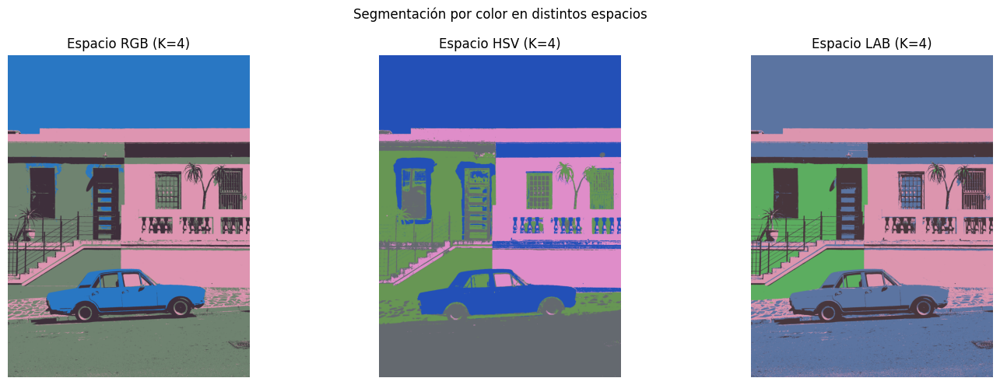

In [27]:
img_objetivo = imgs[0]
k_comparacion = 4
espacios = ['RGB', 'HSV', 'LAB']

fig, axes = plt.subplots(1, len(espacios), figsize=(15, 5))
for ax, espacio in zip(axes, espacios):
    seg = segmentar_en_espacio(img_objetivo, [k_comparacion], espacio)[0]
    ax.imshow(seg)
    ax.axis('off')
    ax.set_title(f'Espacio {espacio} (K={k_comparacion})')
plt.suptitle('Segmentación por color en distintos espacios')
plt.tight_layout()
plt.show()

Para validar con un objeto concreto, segmentamos el vehículo combinando color y posición (igual que en la sección 5), pero usando el espacio **LAB** en lugar de RGB:

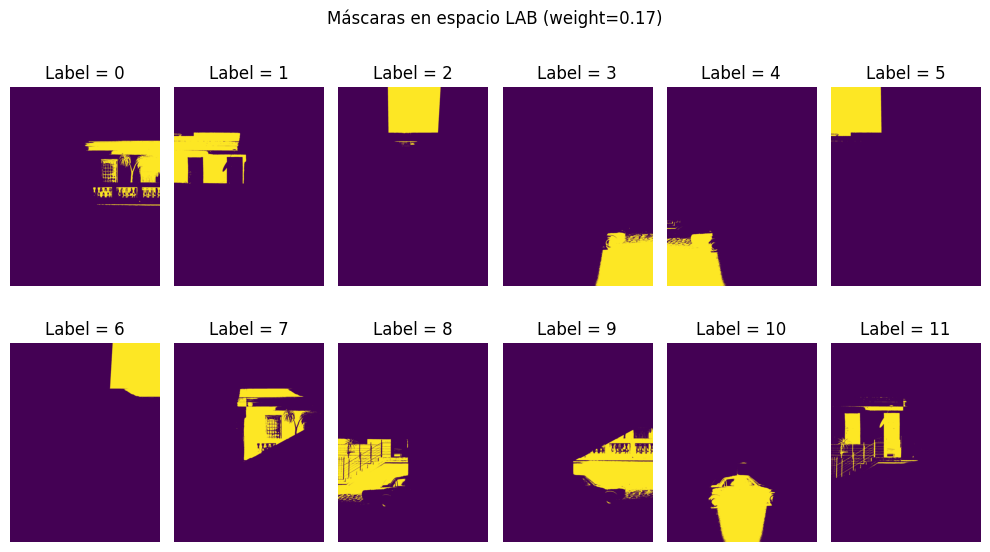

In [28]:
def get_img_masks_espacio(img, k, espacio='RGB', weight=0.17, random_state=2):
    img_conv = convertir_espacio(img, espacio)
    I, J = np.meshgrid(np.arange(img.shape[0]), np.arange(img.shape[1]), indexing='ij')
    idx_list = np.dstack([I, J]).reshape(-1, 2)

    X = img_conv.reshape((-1, 3)).astype(np.float64)
    X = np.hstack([X, idx_list * weight])

    kmeans = KMeans(n_clusters=k, random_state=random_state)
    cluster_labels = kmeans.fit_predict(X)
    segmented_img = cluster_labels.reshape(img.shape[:2])

    cols = k // 2
    rows = k // cols
    fig, ax = plt.subplots(rows, cols, layout='tight', figsize=(10, 6))
    img_idx = 0
    for i in range(rows):
        for j in range(cols):
            mask = (segmented_img == img_idx)
            ax[i, j].imshow(mask)
            ax[i, j].axis('off')
            ax[i, j].set(title=f'Label = {img_idx}')
            img_idx += 1
    plt.suptitle(f'Máscaras en espacio {espacio} (weight={weight})')
    plt.show()
    return segmented_img


# usamos K=12, el mismo valor que en la sección 5 permitió aislar bien el vehículo con RGB
segmentado_lab = get_img_masks_espacio(imgs[0], 12, espacio='LAB', weight=0.17)

**Hallazgos.** En la comparación por color puro (K=4, sin posición), ninguno de los tres espacios aísla limpiamente el vehículo:

- En **RGB**, el cielo y el carro quedan en el **mismo clúster**: ambos son azules suficientemente parecidos en distancia euclidiana como para que, con solo 4 centroides, K-Means no los separe. Es el mismo problema que ya se vio en la sección 5 con `weight=0`.
- En **HSV** ocurre algo similar: cielo y carro vuelven a compartir clúster, aunque la frontera entre las paredes verde y rosada se dibuja distinto (HSV separa mejor zonas con sombra, como la base de la escalera, en un clúster gris aparte).
- En **LAB**, en cambio, el cielo y el carro sí quedan en **clústeres distintos**: el cielo se agrupa en un azul grisáceo apagado y el carro en un azul más saturado. El costo es que ese clúster del carro termina fusionado con el del piso, que tiene un tono perceptualmente parecido. Esto confirma la idea de la investigación: LAB separa mejor colores que a simple vista se ven distintos (cielo/carro), pero no resuelve el problema de fondo, que es que 4 clústeres no alcanzan para separar todos los objetos relevantes de la escena.

**Validación con el objeto de interés.** Al repetir la segmentación del vehículo combinando color LAB y posición (`weight=0.17`), pero ahora con $K=12$ —el mismo valor que en la sección 5 permitió aislar el carro usando RGB—, el resultado es comparable al de RGB: el clúster `Label = 9` captura casi exclusivamente la silueta del carro (un blob alargado y bajo, con la forma característica de un vehículo visto de perfil), mientras que los demás clústeres se reparten el resto de la escena (puertas, escalera, ventanas, palmeras, baranda). Esto confirma que, para este caso, **la ganancia de usar LAB en lugar de RGB no es muy grande una vez que se agrega la posición**: la posición ya resuelve gran parte del problema de separar el carro del resto de la imagen, y el espacio de color influye sobre todo en los casos límite (como la confusión cielo/carro con color puro), no tanto cuando ya hay información espacial disponible.

### Ejercicio 2. Algoritmos sin sesgo hacia la convexidad

K-Means asigna cada píxel a la región de Voronoi de su centroide más cercano, lo que produce siempre fronteras convexas entre clústeres. **DBSCAN**, que ya se estudió en la práctica 12, no tiene esa limitación: define los grupos como regiones densas conectadas, sin ninguna forma predefinida.

Aplicar DBSCAN directamente sobre todos los píxeles de una imagen (cientos de miles o millones) no es viable por el costo de memoria de las consultas de vecindad, así que reducimos la imagen (`cv2.resize`) antes de agruparla. Usamos las mismas heurísticas de la práctica 12 para elegir `eps`: el gráfico de k-distancias.

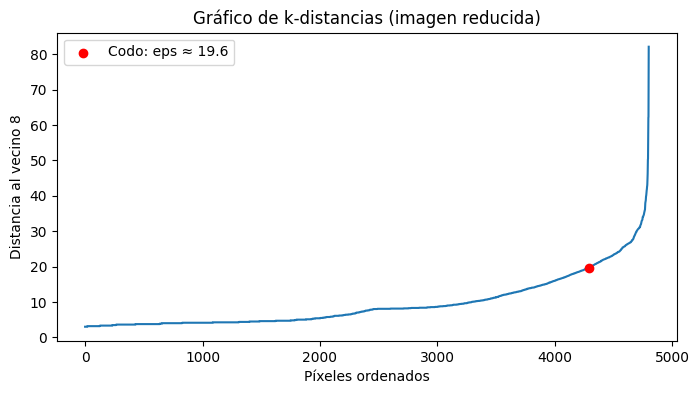

eps estimado: 19.65


In [29]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

img_reducida = cv2.resize(imgs[0], (80, 60), interpolation=cv2.INTER_AREA)

I, J = np.meshgrid(np.arange(img_reducida.shape[0]), np.arange(img_reducida.shape[1]), indexing='ij')
pos = np.dstack([I, J]).reshape(-1, 2).astype(np.float64)
X_color = img_reducida.reshape(-1, 3).astype(np.float64)
# igual que en la sección 5, agregamos la posición con un peso para favorecer regiones contiguas
X_dbscan = np.hstack([X_color, pos * 2.0])

min_samples_img = 8
vecinos_img = NearestNeighbors(n_neighbors=min_samples_img).fit(X_dbscan)
distancias_img, _ = vecinos_img.kneighbors(X_dbscan)
dist_k_img = np.sort(distancias_img[:, -1])

x_norm = np.linspace(0, 1, len(dist_k_img))
y_norm = (dist_k_img - dist_k_img.min()) / (dist_k_img.max() - dist_k_img.min())
idx_codo = np.argmax(x_norm - y_norm)
eps_img = dist_k_img[idx_codo]

plt.figure(figsize=(8, 4))
plt.plot(dist_k_img)
plt.scatter(idx_codo, eps_img, color='red', zorder=3, label=f'Codo: eps ≈ {eps_img:.1f}')
plt.xlabel('Píxeles ordenados')
plt.ylabel(f'Distancia al vecino {min_samples_img}')
plt.title('Gráfico de k-distancias (imagen reducida)')
plt.legend()
plt.show()
print(f'eps estimado: {eps_img:.2f}')

DBSCAN encontró 34 grupos y marcó 5.8% de los píxeles como ruido


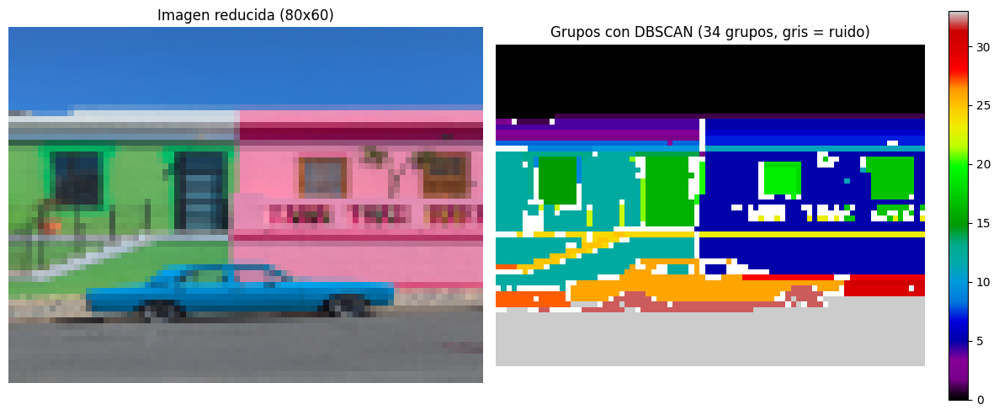

In [30]:
dbscan_img = DBSCAN(eps=eps_img, min_samples=min_samples_img)
etiquetas_dbscan_img = dbscan_img.fit_predict(X_dbscan)

n_grupos_dbscan = len(set(etiquetas_dbscan_img)) - (1 if -1 in etiquetas_dbscan_img else 0)
pct_ruido_dbscan = np.mean(etiquetas_dbscan_img == -1) * 100
print(f'DBSCAN encontró {n_grupos_dbscan} grupos y marcó {pct_ruido_dbscan:.1f}% de los píxeles como ruido')

mapa_etiquetas = etiquetas_dbscan_img.reshape(img_reducida.shape[:2]).astype(float)
mapa_etiquetas[mapa_etiquetas == -1] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_reducida)
axes[0].axis('off')
axes[0].set_title('Imagen reducida (80x60)')
im = axes[1].imshow(mapa_etiquetas, cmap='nipy_spectral')
axes[1].axis('off')
axes[1].set_title(f'Grupos con DBSCAN ({n_grupos_dbscan} grupos, gris = ruido)')
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

**Resultado.** Con `eps ≈ 19.65` (estimado con el codo del gráfico de k-distancias, igual que en la práctica 12) y `min_samples=8`, DBSCAN encontró **34 grupos** y marcó solo **5.8 %** de los píxeles como ruido sobre la imagen reducida a 80×60.

**Cómo cambian los resultados frente a K-Means.** El mapa de grupos muestra que DBSCAN sigue el **contorno real** de los objetos en lugar de imponer fronteras poligonales como K-Means: el límite entre el cielo y el techo de la casa es una línea diagonal irregular que respeta la forma real del tejado, algo que una partición de Voronoi (K-Means) no puede producir directamente, porque sus fronteras entre clústeres son siempre segmentos rectos (o, con la posición agregada, polígonos convexos). El cielo y el piso, que son regiones grandes y de color uniforme, se recuperan como dos grupos claramente definidos y conectados, sin necesidad de fijar su número de antemano: DBSCAN decidió por sí solo que hacían falta 34 grupos, no un valor elegido a priori como $K$.

El costo de esa flexibilidad es visible en la parte de la fachada con más detalle (ventanas, puerta, decoraciones): ahí DBSCAN produce muchos grupos pequeños y fragmentados en lugar de un único grupo "pared", porque la densidad de colores similares y contiguos se rompe con cada detalle arquitectónico. El vehículo, al ser un objeto pequeño dentro de una imagen reducida a 80×60 píxeles, **no aparece como un grupo propio y reconocible**: sus pocos píxeles quedan repartidos entre el grupo del piso y zonas de bajo conteo que no alcanzan `min_samples=8`, a diferencia de lo que lograba K-Means con suficientes clústeres y la posición ponderada (sección 5). Esto ilustra una limitación práctica de DBSCAN para segmentación de imágenes: necesita suficiente resolución (más píxeles por objeto) para que un objeto pequeño alcance la densidad mínima y forme su propio grupo, mientras que K-Means puede aislarlo con solo elegir un $K$ suficientemente grande.

### Ejercicio 3. El parámetro `weight`

En `spatial_img_segmentation` y `get_img_masks`, cada píxel se representa como $(r, g, b, i \cdot \text{weight}, j \cdot \text{weight})$, donde $(i, j)$ es su posición en la imagen. `weight` controla, entonces, **cuánto pesa la posición frente al color** en la distancia euclidiana que usa K-Means: con `weight = 0` el modelo ignora por completo dónde está cada píxel y agrupa solo por color (como en la sección "Segmentación por color"); al aumentar `weight`, la posición empieza a dominar la distancia y el algoritmo tiende a formar regiones compactas en el espacio, aunque mezclen colores distintos.

Probamos valores extremos de `weight` para la segmentación espacial del vehículo:

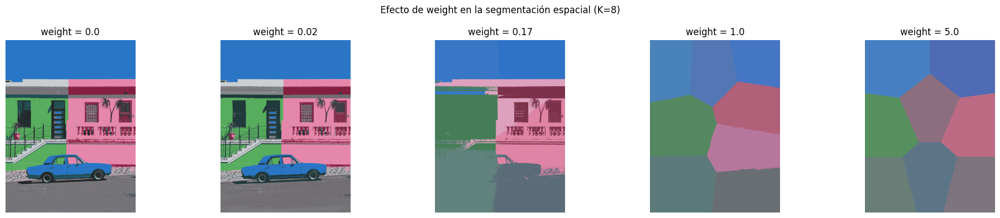

In [31]:
pesos = [0.0, 0.02, 0.17, 1.0, 5.0]
k_pesos = 8

fig, axes = plt.subplots(1, len(pesos), figsize=(4 * len(pesos), 4))
for ax, w in zip(axes, pesos):
    seg_w = spatial_img_segmentation(imgs[0], [k_pesos], weight=w)[0]
    ax.imshow(seg_w)
    ax.axis('off')
    ax.set_title(f'weight = {w}')
plt.suptitle(f'Efecto de weight en la segmentación espacial (K={k_pesos})')
plt.tight_layout()
plt.show()

Comparemos también las máscaras de segmentación para un `weight` casi nulo y uno muy grande:

weight casi nulo (predomina el color):


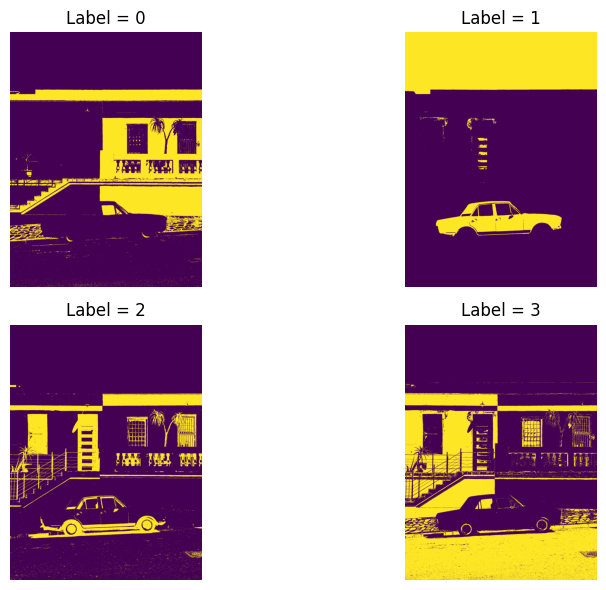

weight muy grande (predomina la posición):


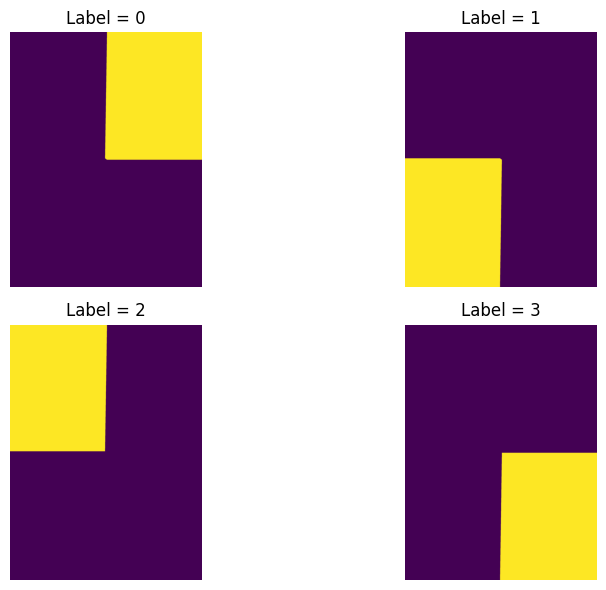

In [32]:
print('weight casi nulo (predomina el color):')
_ = get_img_masks(imgs[0], 4, weight=0.001)

print('weight muy grande (predomina la posición):')
_ = get_img_masks(imgs[0], 4, weight=5.0)

**Efecto de `weight`.** La fila de imágenes con $K=8$ confirma exactamente lo que predice la fórmula del vector $(r, g, b, i \cdot \text{weight}, j \cdot \text{weight})$:

- Con `weight = 0.0` y `weight = 0.02`, el resultado es prácticamente idéntico a segmentar solo por color: se distinguen con nitidez el carro, las ventanas, la puerta, la baranda y hasta las palmeras, porque la posición apenas suma algo a la distancia entre píxeles.
- Con `weight = 0.17` (el valor usado en la sección 5), el resultado ya es visiblemente más "en bloques": las paredes se funden en regiones más grandes y uniformes y el carro deja de distinguirse como un objeto propio dentro de esta corrida con $K=8$, aunque las fronteras siguen relacionándose con el contenido de la imagen.
- Con `weight = 1.0` y `weight = 5.0`, la imagen se reduce a un pequeño número de regiones compactas y aproximadamente poligonales que ya no guardan relación alguna con el color original: son, en la práctica, una partición del plano **solo por posición**, donde el color de cada región es simplemente el promedio de los píxeles que caen ahí. A partir de `weight = 1.0` aumentar aún más el peso (`5.0`) cambia muy poco el resultado, porque la posición ya domina por completo la distancia entre píxeles.

**Máscaras en los extremos (K=4).** Con `weight = 0.001` (casi nulo), el clúster `Label = 1` aísla de forma sorprendentemente limpia la **silueta completa del carro**, sin mezclarse con el cielo, a diferencia de lo que ocurrió en la sección 5 con `weight = 0` exacto (donde el carro sí se confundía con zonas de cielo de color parecido). La diferencia entre `weight = 0` y `weight = 0.001` es mínima en la fórmula, pero alcanza para cambiar el óptimo al que converge K-Means: esto es evidencia de que, cerca de pesos muy pequeños, el resultado puede ser sensible no solo al valor de `weight` sino también a mínimos locales distintos del algoritmo. Con `weight = 5.0`, en cambio, los cuatro clústeres son simplemente cuadrantes rectangulares de la imagen (dos en la mitad superior, dos en la inferior), sin ninguna relación con el contenido: es la confirmación directa de que, con `weight` muy grande, K-Means termina construyendo una partición espacial del plano casi idéntica a la que se vio en la lectura de la semana 10 para $\lambda \to \infty$, donde los segmentos se convierten en bloques de la imagen.